# Etapa 6: rede neural e comparação final

Entrada: `data/processed/renda.csv`, `resultados/referencias.csv` (etapa 3) e `resultados/svm.csv` (etapa 5). Saída: `resultados/rede.csv`.

A rede neural é a mesma da atividade 3 (base de empréstimos), em `src/rede.py`: MLP com ReLU, otimizador Adam e early stopping (10% do treino como validação, paciência de 30 épocas). A grade também é a da atividade 3:

- **arquitetura**: uma camada com 8, 16, 32 ou 64 neurônios, ou duas camadas com (32, 16) ou (64, 32);
- **regularização L2 (alpha)**: 0,0001 ou 0,01;
- **taxa de aprendizado**: 0,001 ou 0,01.

São 24 combinações, avaliadas pelo mesmo protocolo das etapas 3 e 5: 10 seeds, divisão estratificada 80/20, validação cruzada de 5 partes dentro do treino, avaliação única no teste e tempos num único núcleo. As SVMs não são treinadas de novo: seus resultados vêm de `svm.csv`, com as mesmas divisões.

## 0. Configuração

In [1]:
import sys
import ast
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV

from src import avaliacao, config, rede

X, y = avaliacao.carregar()
sensiveis = avaliacao.carregar_sensiveis()
referencias = pd.read_csv(config.RESULTS_DIR / "referencias.csv")
svms = pd.read_csv(config.RESULTS_DIR / "svm.csv")
print(X.shape, "| modelos já avaliados:", referencias["modelo"].unique().tolist() + svms["modelo"].unique().tolist())

# aquecimento: um treino pequeno, descartado
X_tr, X_te, y_tr, y_te = avaliacao.dividir(X, y, 0)
avaliacao.treinar_e_medir(rede.rede(), X_tr.iloc[:1000], y_tr.iloc[:1000], X_te, y_te);

(30139, 10) | modelos já avaliados: ['classe majoritária', 'regra de um corte', 'regressão logística', 'árvore de decisão', 'random forest', 'SVM linear', 'SVM RBF', 'SVM polinomial', 'SVM RBF com pesos']


## 1. Rede neural com busca em grade

In [2]:
def redes(seed):
    cv = avaliacao.validacao_cruzada(seed)
    return {"rede neural": GridSearchCV(rede.rede(seed), rede.GRADE, cv=cv, n_jobs=1)}


inicio = perf_counter()
resultados = avaliacao.rodar_seeds(redes, X, y, aquecer=False)
print(f"tempo total: {(perf_counter() - inicio) / 60:.0f} min")
resultados.to_csv(config.RESULTS_DIR / "rede.csv", index=False)
print("gravado: rede.csv", resultados.shape)

tempo total: 18 min
gravado: rede.csv (10, 14)


## 2. Resultados nas 10 seeds

In [3]:
todos = pd.concat([referencias, svms, resultados], ignore_index=True)
avaliacao.resumir(todos)

,acurácia,F1 macro,F1 >50K,AUC,falsos positivos (média),falsos negativos (média),tempo de treino (s) · mediana,tempo da busca (s) · mediana,tempo de previsão (ms) · mediana
modelo,,,,,,,,,
classe majoritária,75.1 ± 0.0,42.9 ± 0.0,0.0 ± 0.0,50.0 ± 0.0,0.0,1501.0,0.0148,NaN,4.3379
regra de um corte,75.1 ± 0.0,42.9 ± 0.0,0.0 ± 0.0,75.6 ± 0.6,0.0,1501.0,0.0216,NaN,4.8009
regressão logística,84.8 ± 0.3,78.3 ± 0.4,66.5 ± 0.6,90.2 ± 0.4,324.9,591.5,0.0618,NaN,4.5432
árvore de decisão,85.2 ± 0.4,78.4 ± 0.8,66.4 ± 1.6,90.0 ± 0.4,277.4,616.7,0.0551,7.2871,5.0971
random forest,84.3 ± 0.4,78.1 ± 0.6,66.5 ± 0.8,89.1 ± 0.5,390.7,558.7,2.8409,NaN,179.9893
SVM linear,84.8 ± 0.3,78.2 ± 0.3,66.2 ± 0.5,90.2 ± 0.4,310.8,604.5,0.0493,1.1596,4.5044
SVM RBF,85.4 ± 0.4,79.0 ± 0.4,67.5 ± 0.7,88.9 ± 1.0,293.9,587.0,5.7291,477.3944,2015.7247
SVM polinomial,85.2 ± 0.4,78.7 ± 0.4,66.9 ± 0.7,90.2 ± 0.6,298.3,596.4,3.5506,130.4408,487.6405
SVM RBF com pesos,80.9 ± 0.3,77.6 ± 0.3,69.0 ± 0.4,89.8 ± 0.8,929.3,220.6,6.2507,NaN,2283.0701


**Leitura da tabela** (média ± desvio de 10 seeds; tempos em mediana):

- **Rede neural**: 85,2 ± 0,6% de acurácia, F1 macro de 79,4%, F1 da classe >50K de 68,4% e AUC de 90,8%. É o melhor F1 macro e a melhor AUC de todos os modelos; na acurácia, empata com a árvore e a SVM polinomial, logo abaixo da SVM RBF (85,4%).
- **Erros**: entre os modelos sem pesos, a rede tem o menor número de falsos negativos (533, contra 587 da SVM RBF) e um pouco mais de falsos positivos (362, contra 294). Ela corta um pouco mais a favor da classe pequena, sem a troca drástica da versão com pesos.
- **Variação**: os desvios da rede são os maiores entre os modelos que aprendem (0,6 na acurácia, 0,8 no F1 macro, 1,2 no F1 da classe >50K). O resultado depende mais da seed, como a seção 3 explica.

A ordem muda conforme a métrica: pela acurácia, a SVM RBF fica à frente; pelo F1 macro e pela AUC, a rede. As diferenças, de novo, ficam abaixo de 1 ponto, perto do teto de 97,1% que nenhum modelo alcança.

## 3. Hiperparâmetros e épocas

In [4]:
print(resultados["hiperparâmetros"].str.replace("mlp__", "").value_counts().to_string())
print()
print("épocas até o early stopping:", resultados["épocas"].tolist())

hiperparâmetros
{'alpha': 0.0001, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.001}    1
{'alpha': 0.01, 'hidden_layer_sizes': (16,), 'learning_rate_init': 0.001}         1
{'alpha': 0.01, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.01}       1
{'alpha': 0.01, 'hidden_layer_sizes': (16,), 'learning_rate_init': 0.01}          1
{'alpha': 0.0001, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.001}       1
{'alpha': 0.0001, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.001}    1
{'alpha': 0.01, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.01}          1
{'alpha': 0.01, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.001}      1
{'alpha': 0.0001, 'hidden_layer_sizes': (16,), 'learning_rate_init': 0.01}        1
{'alpha': 0.01, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.01}          1

épocas até o early stopping: [33, 41, 41, 60, 86, 52, 57, 82, 37, 36]


Cada seed escolhe uma combinação diferente: 10 combinações em 10 seeds, com uma ou duas camadas, de 16 a 64 neurônios, e os dois valores de alpha e de taxa de aprendizado. Nenhuma configuração se destaca na validação cruzada: várias arquiteturas chegam ao mesmo resultado, e a escolha muda com o sorteio. É o mesmo comportamento da árvore na etapa 3 e o oposto da SVM, que escolheu C = 1 em 9 das 10 seeds.

O early stopping para entre 33 e 86 épocas. A rede aprende o que dá para aprender em poucas dezenas de passagens pelos dados; daí em diante, a validação para de melhorar. Essa variação de arquitetura e de ponto de parada explica os desvios maiores da seção 2.

## 4. Comparações seed a seed

In [5]:
def comparar(metrica):
    pares = todos.pivot(index="seed", columns="modelo", values=metrica)
    comparacoes = {
        "rede neural − SVM RBF": ("rede neural", "SVM RBF"),
        "rede neural − SVM polinomial": ("rede neural", "SVM polinomial"),
        "rede neural − SVM linear": ("rede neural", "SVM linear"),
        "rede neural − regressão logística": ("rede neural", "regressão logística"),
        "rede neural − árvore de decisão": ("rede neural", "árvore de decisão"),
    }
    return pd.DataFrame({
        nome: {"diferença média (pontos)": round(100 * (pares[a] - pares[b]).mean(), 2),
               "desvio (pontos)": round(100 * (pares[a] - pares[b]).std(), 2),
               "seeds com diferença positiva": int(((pares[a] - pares[b]) > 0).sum())}
        for nome, (a, b) in comparacoes.items()
    }).T


for metrica in ["acurácia", "F1 macro", "AUC"]:
    print(metrica)
    display(comparar(metrica))

acurácia


,diferença média (pontos),desvio (pontos),seeds com diferença positiva
rede neural − SVM RBF,-0.22,0.40,2.0
rede neural − SVM polinomial,0.01,0.46,5.0
rede neural − SVM linear,0.35,0.45,9.0
rede neural − regressão logística,0.37,0.43,9.0
rede neural − árvore de decisão,-0.00,0.45,5.0


F1 macro


,diferença média (pontos),desvio (pontos),seeds com diferença positiva
rede neural − SVM RBF,0.32,0.49,7.0
rede neural − SVM polinomial,0.68,0.62,9.0
rede neural − SVM linear,1.14,0.59,10.0
rede neural − regressão logística,1.02,0.53,10.0
rede neural − árvore de decisão,0.93,0.99,10.0


AUC


,diferença média (pontos),desvio (pontos),seeds com diferença positiva
rede neural − SVM RBF,1.96,0.66,10.0
rede neural − SVM polinomial,0.62,0.36,10.0
rede neural − SVM linear,0.66,0.28,10.0
rede neural − regressão logística,0.64,0.29,10.0
rede neural − árvore de decisão,0.88,0.28,10.0


- **Rede contra SVM RBF**: na acurácia, a SVM RBF ganha (−0,22 ponto, rede à frente em só 2 seeds); no F1 macro, a rede fica à frente em 7 das 10 (+0,32), o que é praticamente empate; na AUC, a rede ganha nas 10 seeds (+1,96 ponto).
- **Rede contra SVM polinomial e árvore**: empate na acurácia (5 de 10 nos dois casos); a rede ganha no F1 macro (9 e 10 seeds) e na AUC (10 seeds).
- **Rede contra SVM linear e regressão logística**: +0,35 ponto de acurácia (9 de 10), cerca de +1 ponto de F1 macro e +0,65 de AUC, nas 10 seeds. A fronteira curva da rede ganha das fronteiras retas, como a do RBF ganhava.

**A AUC é onde a rede se destaca**: vence os cinco modelos nas 10 seeds. A rede é treinada para prever probabilidades (minimiza a perda logística), então suas notas ordenam bem as pessoas em toda a faixa, não só perto da fronteira. A SVM RBF é treinada só para acertar o lado da fronteira, e o gamma alto que a busca escolhe piora a ordem, como a etapa 5 mostrou. Pela acurácia, a SVM RBF é o melhor modelo; para ordenar pessoas por chance de renda alta, a rede é.

## 5. Acerto, erros e tempo de todos os modelos

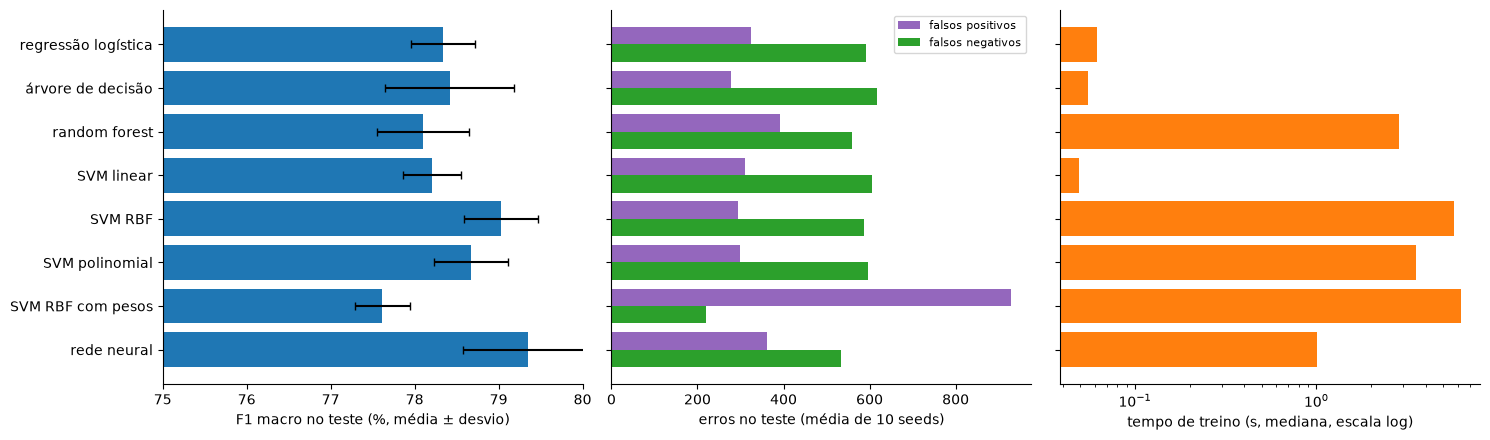

,tempo de treino (s),tempo da busca (s),tempo de previsão (ms)
modelo,,,
regressão logística,0.062,NaN,4.543
árvore de decisão,0.055,7.287,5.097
random forest,2.841,NaN,179.989
SVM linear,0.049,1.160,4.504
SVM RBF,5.729,477.394,2015.725
SVM polinomial,3.551,130.441,487.641
SVM RBF com pesos,6.251,NaN,2283.070
rede neural,1.013,104.148,5.589


In [6]:
ordem = ["regressão logística", "árvore de decisão", "random forest", "SVM linear",
         "SVM RBF", "SVM polinomial", "SVM RBF com pesos", "rede neural"]
grupos = todos.groupby("modelo")

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
media, desvio = grupos["F1 macro"].mean()[ordem], grupos["F1 macro"].std()[ordem]
eixos[0].barh(ordem, 100 * media, xerr=100 * desvio, color="tab:blue", capsize=3)
eixos[0].set_xlim(75, 80)
eixos[0].set_xlabel("F1 macro no teste (%, média ± desvio)")

erros = grupos[["falsos positivos", "falsos negativos"]].mean().loc[ordem]
eixos[1].barh(np.arange(len(ordem)) - 0.2, erros["falsos positivos"], height=0.4, color="tab:purple", label="falsos positivos")
eixos[1].barh(np.arange(len(ordem)) + 0.2, erros["falsos negativos"], height=0.4, color="tab:green", label="falsos negativos")
eixos[1].set_yticks(range(len(ordem)), [])
eixos[1].set_xlabel("erros no teste (média de 10 seeds)")
eixos[1].legend(fontsize=8)

tempo = grupos["tempo de treino (s)"].median()[ordem]
eixos[2].barh(ordem, tempo, color="tab:orange")
eixos[2].set_xscale("log")
eixos[2].set_yticks(range(len(ordem)), [])
eixos[2].set_xlabel("tempo de treino (s, mediana, escala log)")
for ax in eixos:
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

grupos[["tempo de treino (s)", "tempo da busca (s)", "tempo de previsão (ms)"]].median().loc[ordem].round(3)

**Treino**: a rede treina em 1,0 s, entre a SVM linear (0,05 s) e a SVM RBF (5,7 s). **Busca**: 1,7 minuto por seed (120 treinos), contra 8 minutos da SVM RBF (80 treinos). As 10 seeds levaram 18 minutos, contra 80 da busca do RBF.

**Previsão**: 5,6 ms para as 6.028 pessoas do teste, como a regressão logística e cerca de 360 vezes menos que a SVM RBF (2,0 s). Depois de treinada, a rede é só algumas multiplicações de matrizes por pessoa, e esse custo não depende do tamanho do treino. Na SVM com kernel, o custo da previsão cresce com o número de vetores de suporte, que cresce com o treino.

## 6. Erros por sexo e raça

O mesmo cálculo da etapa 5, agora para a rede: em cada seed, a rede final (com os hiperparâmetros escolhidos na seed) prevê o teste, e os erros são separados por grupo. Ao lado, os valores do SVM RBF sem pesos, lidos de `svm_erros_por_grupo.csv`. Médias das 10 seeds.

In [7]:
def parametros_rede(seed):
    texto = resultados.query("seed == @seed")["hiperparâmetros"].iloc[0]
    return {k.replace("mlp__", ""): v for k, v in ast.literal_eval(texto).items()}


linhas = []
for seed in config.SEEDS:
    X_tr, X_te, y_tr, y_te = avaliacao.dividir(X, y, seed)
    previsto = rede.rede(seed, **parametros_rede(seed)).fit(X_tr, y_tr).predict(X_te)
    teste = sensiveis.loc[X_te.index].assign(real=y_te.to_numpy(), previsto=previsto)
    for coluna in config.SENSIVEIS:
        for grupo, g in teste.groupby(coluna):
            linhas.append({
                "modelo": "rede neural", "atributo": config.NOMES[coluna], "grupo": grupo, "seed": seed,
                "pessoas no teste": len(g),
                "% real >50K": 100 * g["real"].mean(),
                "% previsto >50K": 100 * g["previsto"].mean(),
                "taxa de falsos negativos (%)": 100 * ((g["previsto"] == 0) & (g["real"] == 1)).sum() / max((g["real"] == 1).sum(), 1),
                "taxa de falsos positivos (%)": 100 * ((g["previsto"] == 1) & (g["real"] == 0)).sum() / max((g["real"] == 0).sum(), 1),
            })
por_grupo = pd.DataFrame(linhas)
por_grupo.to_csv(config.RESULTS_DIR / "rede_erros_por_grupo.csv", index=False)

svm_grupo = pd.read_csv(config.RESULTS_DIR / "svm_erros_por_grupo.csv").query("modelo == 'SVM RBF'")
pd.concat([svm_grupo, por_grupo]).drop(columns=["seed", "pessoas no teste"]) \
    .groupby(["atributo", "grupo", "modelo"], sort=False).mean().round(1)

% real >50K  % previsto >50K  \
atributo grupo              modelo                                      
raça     Amer-Indian-Eskimo SVM RBF             11.0              6.6   
         Asian-Pac-Islander SVM RBF             27.3             24.1   
         Black              SVM RBF             13.5              9.6   
         Other              SVM RBF             10.6              8.0   
         White              SVM RBF             26.3             21.3   
sexo     Female             SVM RBF             11.6              8.0   
         Male               SVM RBF             31.4             25.9   
raça     Amer-Indian-Eskimo rede neural         11.0              9.3   
         Asian-Pac-Islander rede neural         27.3             24.1   
         Black              rede neural         13.5             10.8   
         Other              rede neural         10.6              8.8   
         White              rede neural         26.3             23.5   
sexo     Female             rede neural         11.6              9.0   
         Male               rede neural         31.4             28.4   

                                         taxa de falsos negativos (%)  \
atributo grupo              modelo                                      
raça     Amer-Indian-Eskimo SVM RBF                              54.9   
         Asian-Pac-Islander SVM RBF                              35.2   
         Black              SVM RBF                              45.0   
         Other              SVM RBF                              50.8   
         White              SVM RBF                              38.8   
sexo     Female             SVM RBF                              47.6   
         Male               SVM RBF                              37.6   
raça     Amer-Indian-Eskimo rede neural                          56.7   
         Asian-Pac-Islander rede neural                          36.0   
         Black              rede neural                          41.1   
         Other              rede neural                          48.3   
         White              rede neural                          35.1   
sexo     Female             rede neural                          43.6   
         Male               rede neural                          34.0   

                                         taxa de falsos positivos (%)  
atributo grupo              modelo                                     
raça     Amer-Indian-Eskimo SVM RBF                               1.8  
         Asian-Pac-Islander SVM RBF                               8.8  
         Black              SVM RBF                               2.5  
         Other              SVM RBF                               2.4  
         White              SVM RBF                               7.0  
sexo     Female             SVM RBF                               2.2  
         Male               SVM RBF                               9.2  
raça     Amer-Indian-Eskimo rede neural                           5.0  
         Asian-Pac-Islander rede neural                           9.2  
         Black              rede neural                           3.3  
         Other              rede neural                           3.1  
         White              rede neural                           8.6  
sexo     Female             rede neural                           2.8  
         Male               rede neural                          11.3

A rede repete o padrão da SVM RBF. Entre as mulheres de renda alta, deixa passar 43,6%; entre os homens, 34,0%. A distância entre os sexos fica quase igual à da SVM (9,6 pontos, contra 10,0). Os falsos positivos continuam menores para as mulheres (2,8%) que para os homens (11,3%). Na raça, os números também acompanham a SVM: 35,1% de falsos negativos entre brancos e 41,1% entre negros.

A rede subestima um pouco menos os dois sexos (prevê 9,0% de renda alta entre as mulheres, contra 11,6% reais, e 28,4% entre os homens, contra 31,4%), porque corta um pouco mais a favor da classe pequena. Mas a diferença entre os grupos não muda. Dois modelos de famílias diferentes, treinados sem sexo e sem raça, produzem a mesma diferença: ela vem dos dados e dos atributos relacionados ao sexo, não de um modelo em particular.

**Resultado final** (10 seeds, mesmo protocolo, mesmas divisões):

- **Melhor acurácia**: SVM RBF, 85,4%, à frente da rede em 8 das 10 seeds. Empatam logo abaixo a rede, a SVM polinomial e a árvore ajustada (85,2%).
- **Melhor F1 macro e melhor AUC**: rede neural, 79,4% e 90,8%. No F1 macro, a margem sobre a SVM RBF é pequena (7 de 10 seeds); na AUC, a rede vence todos os modelos nas 10 seeds.
- **Fronteira curva contra reta**: a SVM RBF e a rede ganham das fronteiras retas (SVM linear e regressão logística) por cerca de meio ponto de acurácia e 1 ponto de F1 macro.
- **Falsos negativos**: entre os modelos sem pesos, a rede deixa passar menos pessoas de renda alta (533, contra 587 da SVM RBF). Para reduzir muito mais, só com pesos por classe, com o triplo de falsos positivos.
- **Custo**: a rede busca em 1,7 minuto por seed e prevê em 5,6 ms; a SVM RBF, em 8 minutos e 2,0 s.
- **Erros por grupo**: a rede e a SVM erram mais com as mulheres de renda alta (cerca de 10 pontos a mais de falsos negativos que com os homens), sem usar o sexo.

Nesta base, a SVM RBF é competitiva em acurácia, mas não domina: a rede neural alcança o mesmo nível com melhor F1 macro, melhor AUC e uma fração do custo. A vantagem de qualquer modelo flexível sobre uma fronteira reta é de menos de 1 ponto.